# Generate Tennis Ball Coordinate JSON

This notebook runs only the TrackNet ball detector and writes ball-coordinate JSON for `trajectory_optimization_lab.ipynb`.

Outputs:
- `ball_coords_raw.json`: compact format with `ball_coords[*].pixel`.
- `ball_coords_match_frames.json`: `match_frames`-compatible format that the trajectory lab can read directly.
- `ball_candidates_overlay.mp4`: 每帧所有 Hough 候选点的调试可视化。


In [11]:
from __future__ import annotations

import json
import os
import sys
from collections import deque
from datetime import datetime, timezone
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import torch
from tqdm.auto import tqdm

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name in {"scripts", "experiments"} and PROJECT_ROOT.parent.name == "cv":
    PROJECT_ROOT = PROJECT_ROOT.parents[1]
elif PROJECT_ROOT.name == "cv":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from cv.config import DEFAULT_BALL_MODEL_PATH, INPUT_DIR, OUTPUT_DIR as CV_OUTPUT_DIR
from cv.models.ball_tracking.general import postprocess
from cv.models.ball_tracking.model import BallTrackerNet


## 1. Configure Paths

Set `BALL_MODEL_PATH` to your TrackNet weight file. This repo currently expects names like `model_best.pt`, but weights are usually kept outside git.

In [ ]:
INPUT_VIDEO_PATH = INPUT_DIR / "real60.mp4"

# Override this manually if your weights live elsewhere.
CANDIDATE_BALL_MODEL_PATHS = [
    DEFAULT_BALL_MODEL_PATH,
    PROJECT_ROOT / "weights/model_best.pt",
]
BALL_MODEL_PATH = next((path for path in CANDIDATE_BALL_MODEL_PATHS if path.exists()), CANDIDATE_BALL_MODEL_PATHS[0])

OUTPUT_DIR = CV_OUTPUT_DIR
RAW_OUTPUT_PATH = OUTPUT_DIR / "ball_coords_raw.json"
MATCH_FRAMES_OUTPUT_PATH = OUTPUT_DIR / "ball_coords_match_frames.json"
RAW_POINTS_VIDEO_PATH = OUTPUT_DIR / "ball_coords_raw_overlay.mp4"

# Useful for fast iteration. Set to None for the whole video.
MAX_FRAMES = None

# TrackNet predicts a 0-255 grayscale class per pixel. Values >= 128 are treated as ball-like heat.
BALLNESS_CLASS_THRESHOLD = 128
CONFIDENCE_PATCH_RADIUS = 3
# Hough often returns many overlapping circles around one heat blob. Cluster them in 640x360 heatmap pixels.
CANDIDATE_CLUSTER_DISTANCE_PX = 10.0

# Viterbi-lite main-ball tracking. These are pixel-space values on the original video.
TRACKING_MAX_CANDIDATES_PER_FRAME = 8
TRACKING_DETECTION_WEIGHT = 3.0
TRACKING_MEMBER_BONUS_WEIGHT = 0.15
TRACKING_PREDICTION_SIGMA_PX = 90.0
TRACKING_ACCELERATION_SIGMA_PX = 140.0
TRACKING_MAX_LINK_DISTANCE_PX = 180.0
TRACKING_DISTANCE_DT_CAP = 2
TRACKING_MAX_RAW_JUMP_PX = 170.0
TRACKING_RAW_JUMP_PENALTY = 8.0
TRACKING_RAW_JUMP_HARD_REJECT_FACTOR = 1.8
TRACKING_PERSPECTIVE_FAR_SCALE = 0.65
TRACKING_PERSPECTIVE_NEAR_SCALE = 2.30
TRACKING_REACQUIRE_AFTER_MISSING_FRAMES = 5
TRACKING_REACQUIRE_MISSING_SCORE_FLOOR = -6.0
TRACKING_DISTANCE_WEIGHT = 1.0
TRACKING_ACCELERATION_WEIGHT = 0.45
TRACKING_MISSING_FRAME_PENALTY = 1.4
TRACKING_FAR_JUMP_PENALTY = 4.0
TRACKING_STATIC_SPEED_PX = 1.5
TRACKING_STATIC_PENALTY = 0.35


print("video:", INPUT_VIDEO_PATH)
print("ball model:", BALL_MODEL_PATH)
print("raw output:", RAW_OUTPUT_PATH)
print("match_frames output:", MATCH_FRAMES_OUTPUT_PATH)
print("overlay video:", RAW_POINTS_VIDEO_PATH)


video: /Users/mac/PycharmProjects/tennis_data_master/cv/data/input/real.mp4
ball model: /Users/mac/PycharmProjects/tennis_data_master/cv/models/weights/model_best.pt
raw output: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/ball_coords_raw.json
match_frames output: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/ball_coords_match_frames.json
overlay video: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/ball_coords_raw_overlay.mp4


In [13]:
if not INPUT_VIDEO_PATH.exists():
    raise FileNotFoundError(f"Input video not found: {INPUT_VIDEO_PATH}")
if not BALL_MODEL_PATH.exists():
    raise FileNotFoundError(
        "TrackNet ball model not found. Set BALL_MODEL_PATH to model_best.pt before running. "
        f"Current value: {BALL_MODEL_PATH}"
    )

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 2. Load Model

This notebook calls `postprocess(..., orig_w=video_width, orig_h=video_height)` directly, so the exported pixel coordinates match the source video resolution.

In [14]:
def choose_torch_device():
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


device = choose_torch_device()
model = BallTrackerNet()
state_dict = torch.load(BALL_MODEL_PATH, map_location="cpu", weights_only=True)
model.load_state_dict(state_dict)
model.to(device)
model.eval()
print("device:", device)


device: mps


## 3. Run Ball Detection

In [15]:
def extract_candidate_circles(feature_map, *, input_w=640, input_h=360, orig_w=1920, orig_h=1080):
    feature_map = feature_map.reshape((input_h, input_w))
    feature_map = (feature_map * 255).astype(np.uint8)
    _, heatmap = cv2.threshold(feature_map, 127, 255, cv2.THRESH_BINARY)

    circles = cv2.HoughCircles(
        heatmap,
        cv2.HOUGH_GRADIENT,
        dp=1,
        minDist=1,
        param1=50,
        param2=2,
        minRadius=2,
        maxRadius=7,
    )

    raw_candidates = []
    if circles is None or len(circles) == 0:
        return raw_candidates

    scale_x = orig_w / input_w
    scale_y = orig_h / input_h
    for rank, circle in enumerate(circles[0], start=1):
        cx, cy, radius = circle
        raw_candidates.append({
            "raw_rank": rank,
            "pixel": [round((float(cx) + 0.5) * scale_x, 2), round((float(cy) + 0.5) * scale_y, 2)],
            "heatmap_pixel": [round(float(cx), 2), round(float(cy), 2)],
            "radius": round(float(radius), 2),
        })
    return raw_candidates


def score_candidate(candidate, *, ballness, expected_heat, peak_probability, predicted_class, max_class_value, patch_radius=3):
    cx, cy = candidate["heatmap_pixel"]
    input_h, input_w = ballness.shape
    mx = int(np.clip(round(cx), 0, input_w - 1))
    my = int(np.clip(round(cy), 0, input_h - 1))
    y1, y2 = max(0, my - patch_radius), min(input_h, my + patch_radius + 1)
    x1, x2 = max(0, mx - patch_radius), min(input_w, mx + patch_radius + 1)

    ballness_patch = ballness[y1:y2, x1:x2]
    heat_patch = expected_heat[y1:y2, x1:x2]
    peak_patch = peak_probability[y1:y2, x1:x2]
    class_patch = predicted_class[y1:y2, x1:x2]

    candidate["confidence"] = round(float(ballness_patch.max().detach().cpu()), 4)
    candidate["heat_conf"] = round(float(heat_patch.max().detach().cpu()), 4)
    candidate["peak_class_probability"] = round(float(peak_patch.max().detach().cpu()), 4)
    candidate["predicted_intensity"] = round(float(class_patch.max().detach().cpu()) / max(max_class_value, 1), 4)
    candidate["score"] = candidate["confidence"]
    return candidate


def cluster_candidate_circles(raw_candidates, *, cluster_distance_px=CANDIDATE_CLUSTER_DISTANCE_PX):
    if not raw_candidates:
        return []

    remaining = sorted(raw_candidates, key=lambda item: item.get("score", 0.0), reverse=True)
    clusters = []
    while remaining:
        seed = remaining.pop(0)
        sx, sy = seed["heatmap_pixel"]
        members = [seed]
        keep = []
        for candidate in remaining:
            cx, cy = candidate["heatmap_pixel"]
            if float(np.hypot(cx - sx, cy - sy)) <= cluster_distance_px:
                members.append(candidate)
            else:
                keep.append(candidate)
        remaining = keep

        weights = np.array([max(member.get("score", 0.0), 1e-6) for member in members], dtype=np.float64)
        heatmap_points = np.array([member["heatmap_pixel"] for member in members], dtype=np.float64)
        pixel_points = np.array([member["pixel"] for member in members], dtype=np.float64)
        center_heatmap = np.average(heatmap_points, axis=0, weights=weights)
        center_pixel = np.average(pixel_points, axis=0, weights=weights)
        best_member = max(members, key=lambda item: item.get("score", 0.0))

        clusters.append({
            "rank": 0,
            "pixel": [round(float(center_pixel[0]), 2), round(float(center_pixel[1]), 2)],
            "heatmap_pixel": [round(float(center_heatmap[0]), 2), round(float(center_heatmap[1]), 2)],
            "radius": round(float(np.mean([member.get("radius", 0.0) for member in members])), 2),
            "score": round(float(best_member.get("score", 0.0)), 4),
            "confidence": best_member.get("confidence"),
            "heat_conf": best_member.get("heat_conf"),
            "peak_class_probability": best_member.get("peak_class_probability"),
            "predicted_intensity": best_member.get("predicted_intensity"),
            "member_count": len(members),
            "raw_ranks": [member["raw_rank"] for member in members],
        })

    clusters.sort(key=lambda item: item.get("score", 0.0), reverse=True)
    for rank, cluster in enumerate(clusters, start=1):
        cluster["rank"] = rank
    return clusters


def infer_ball_3_frames(model, frames_3, *, device, orig_w, orig_h):
    """Run TrackNet on three frames and return ball pixel plus softmax confidence."""
    f2, f1, f0 = frames_3  # oldest, middle, newest; mirrors the existing pipeline order.
    input_w, input_h = 640, 360
    img2 = cv2.resize(f2, (input_w, input_h))
    img1 = cv2.resize(f1, (input_w, input_h))
    img0 = cv2.resize(f0, (input_w, input_h))

    imgs = np.concatenate((img0, img1, img2), axis=2).astype(np.float32) / 255.0
    imgs = np.rollaxis(imgs, 2, 0)
    inp = np.expand_dims(imgs, axis=0)

    with torch.no_grad():
        out = model(torch.from_numpy(inp).float().to(device))

    n_classes = int(out.shape[1])
    logits = out.reshape(1, n_classes, input_h, input_w)
    probs = torch.softmax(logits, dim=1)[0]
    class_values = torch.arange(n_classes, device=probs.device, dtype=probs.dtype).view(n_classes, 1, 1)
    expected_heat = (probs * class_values).sum(dim=0) / max(n_classes - 1, 1)
    ballness = probs[BALLNESS_CLASS_THRESHOLD:].sum(dim=0)
    peak_class_probability, pred_cls_tensor = probs.max(dim=0)

    output = pred_cls_tensor.detach().cpu().numpy()
    raw_candidates = extract_candidate_circles(output, input_w=input_w, input_h=input_h, orig_w=orig_w, orig_h=orig_h)
    for candidate in raw_candidates:
        score_candidate(
            candidate,
            ballness=ballness,
            expected_heat=expected_heat,
            peak_probability=peak_class_probability,
            predicted_class=pred_cls_tensor,
            max_class_value=n_classes - 1,
            patch_radius=CONFIDENCE_PATCH_RADIUS,
        )
    candidates = cluster_candidate_circles(raw_candidates)
    x, y = postprocess(output, input_w=input_w, input_h=input_h, orig_w=orig_w, orig_h=orig_h)

    pixel = None
    confidence = None
    heat_conf = None
    peak_class_probability_value = None
    predicted_intensity = None
    if x is not None and y is not None and 0 <= x <= orig_w and 0 <= y <= orig_h:
        mx = int(np.clip(round((x / orig_w) * input_w - 0.5), 0, input_w - 1))
        my = int(np.clip(round((y / orig_h) * input_h - 0.5), 0, input_h - 1))
        radius = CONFIDENCE_PATCH_RADIUS
        y1, y2 = max(0, my - radius), min(input_h, my + radius + 1)
        x1, x2 = max(0, mx - radius), min(input_w, mx + radius + 1)

        ballness_patch = ballness[y1:y2, x1:x2]
        heat_patch = expected_heat[y1:y2, x1:x2]
        peak_prob_patch = peak_class_probability[y1:y2, x1:x2]
        pred_cls_patch = pred_cls_tensor[y1:y2, x1:x2]

        confidence = float(ballness_patch.max().detach().cpu())
        heat_conf = float(heat_patch.max().detach().cpu())
        peak_class_probability_value = float(peak_prob_patch.max().detach().cpu())
        predicted_intensity = float(pred_cls_patch.max().detach().cpu()) / max(n_classes - 1, 1)
        pixel = [round(float(x), 2), round(float(y), 2)]

    return {
        "pixel": pixel,
        "confidence": round(confidence, 4) if confidence is not None else None,
        "heat_conf": round(heat_conf, 4) if heat_conf is not None else None,
        "peak_class_probability": round(peak_class_probability_value, 4) if peak_class_probability_value is not None else None,
        "predicted_intensity": round(predicted_intensity, 4) if predicted_intensity is not None else None,
        "raw_candidates": raw_candidates,
        "candidates": candidates,
        "candidate_cluster_distance_px": CANDIDATE_CLUSTER_DISTANCE_PX,
        "confidence_method": f"softmax_probability_intensity_ge_{BALLNESS_CLASS_THRESHOLD}",
    }


cap = cv2.VideoCapture(str(INPUT_VIDEO_PATH))
if not cap.isOpened():
    raise RuntimeError(f"Could not open video: {INPUT_VIDEO_PATH}")

fps = float(cap.get(cv2.CAP_PROP_FPS))
frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
target_frames = min(total_frames, MAX_FRAMES) if MAX_FRAMES is not None else total_frames

ball_coords = []
frame_buffer = deque(maxlen=3)

progress = tqdm(total=target_frames, desc="TrackNet ball detection")
frame_index = 0
while frame_index < target_frames:
    ok, frame = cap.read()
    if not ok:
        break

    frame_buffer.append(frame.copy())
    detection = {
        "pixel": None,
        "confidence": None,
        "heat_conf": None,
        "peak_class_probability": None,
        "predicted_intensity": None,
        "raw_candidates": [],
        "candidates": [],
        "candidate_cluster_distance_px": CANDIDATE_CLUSTER_DISTANCE_PX,
        "confidence_method": f"softmax_probability_intensity_ge_{BALLNESS_CLASS_THRESHOLD}",
    }
    if len(frame_buffer) == 3:
        detection = infer_ball_3_frames(
            model,
            list(frame_buffer),
            device=device,
            orig_w=frame_width,
            orig_h=frame_height,
        )
    pixel = detection["pixel"]
    confidence = detection["confidence"]
    heat_conf = detection["heat_conf"]
    peak_class_probability = detection["peak_class_probability"]
    predicted_intensity = detection["predicted_intensity"]

    item = {
        "frame_index": frame_index,
        "time_sec": round(frame_index / fps, 3) if fps > 0 else 0.0,
        "pixel": pixel,
        "confidence": confidence,
        "heat_conf": heat_conf,
        "peak_class_probability": peak_class_probability,
        "predicted_intensity": predicted_intensity,
    }
    item["confidence_method"] = detection["confidence_method"]
    item["raw_candidates"] = detection["raw_candidates"]
    item["candidates"] = detection["candidates"]
    item["candidate_cluster_distance_px"] = detection["candidate_cluster_distance_px"]
    ball_coords.append(item)
    frame_index += 1
    progress.update(1)

cap.release()
progress.close()

detected = sum(item["pixel"] is not None for item in ball_coords)
valid_confidences = [item["confidence"] for item in ball_coords if item.get("confidence") is not None]
print(f"frames={len(ball_coords):,}, detections={detected:,}, ratio={detected / max(len(ball_coords), 1):.3f}")
if valid_confidences:
    print(
        "confidence:",
        f"mean={np.mean(valid_confidences):.3f}",
        f"p10={np.percentile(valid_confidences, 10):.3f}",
        f"p50={np.percentile(valid_confidences, 50):.3f}",
        f"p90={np.percentile(valid_confidences, 90):.3f}",
    )


TrackNet ball detection: 100%|██████████| 433/433 [01:48<00:00,  3.97it/s]

frames=433, detections=352, ratio=0.813
confidence: mean=0.962 p10=0.942 p50=0.995 p90=0.999


## 4. Select Main Ball With Viterbi-lite Tracking

This step chooses one temporally consistent ball path from the clustered per-frame candidates.


In [16]:
def candidate_pixel(candidate):
    pixel = candidate.get("pixel")
    if not pixel:
        return None
    return np.array(pixel, dtype=np.float64)


def candidate_emission_score(candidate):
    confidence = float(candidate.get("confidence") or candidate.get("score") or 0.0)
    member_count = int(candidate.get("member_count") or 1)
    return (
        TRACKING_DETECTION_WEIGHT * confidence
        + TRACKING_MEMBER_BONUS_WEIGHT * float(np.log1p(max(member_count, 1)))
    )


def tracking_perspective_scale(point_y):
    if frame_height <= 0 or point_y is None or not np.isfinite(point_y):
        return 1.0
    y_ratio = float(np.clip(float(point_y) / float(frame_height), 0.0, 1.0))
    return TRACKING_PERSPECTIVE_FAR_SCALE + y_ratio * (TRACKING_PERSPECTIVE_NEAR_SCALE - TRACKING_PERSPECTIVE_FAR_SCALE)


def transition_score(prev_state, candidate_pixel_value):
    if prev_state["last_pixel"] is None:
        return 0.0, None, None, None, None, None, None, None, None, np.zeros(2, dtype=np.float64)

    gap = int(prev_state["gap"])
    dt = max(gap + 1, 1)
    effective_dt = min(dt, TRACKING_DISTANCE_DT_CAP)
    predicted = prev_state["last_pixel"] + prev_state["velocity"] * dt
    distance = float(np.linalg.norm(candidate_pixel_value - predicted))
    # Keep raw px/frame for diagnostics, but cap dt for scoring so long gaps do not over-dilute jumps.
    distance_per_frame = distance / dt
    distance_per_effective_frame = distance / effective_dt
    perspective_scale = tracking_perspective_scale(candidate_pixel_value[1])
    raw_jump_limit = TRACKING_MAX_RAW_JUMP_PX * float(np.sqrt(dt)) * perspective_scale
    new_velocity = (candidate_pixel_value - prev_state["last_pixel"]) / dt
    acceleration = float(np.linalg.norm(new_velocity - prev_state["velocity"]))

    distance_penalty = TRACKING_DISTANCE_WEIGHT * (distance_per_effective_frame / TRACKING_PREDICTION_SIGMA_PX) ** 2
    acceleration_penalty = TRACKING_ACCELERATION_WEIGHT * (acceleration / TRACKING_ACCELERATION_SIGMA_PX) ** 2

    link_limit = TRACKING_MAX_LINK_DISTANCE_PX
    far_jump_penalty = 0.0
    if distance_per_effective_frame > link_limit:
        far_jump_penalty = TRACKING_FAR_JUMP_PENALTY * ((distance_per_effective_frame - link_limit) / max(link_limit, 1.0)) ** 2

    raw_jump_penalty = 0.0
    if distance > raw_jump_limit:
        raw_jump_penalty = TRACKING_RAW_JUMP_PENALTY * ((distance - raw_jump_limit) / max(raw_jump_limit, 1.0)) ** 2
    if distance > raw_jump_limit * TRACKING_RAW_JUMP_HARD_REJECT_FACTOR:
        raw_jump_penalty += 1_000_000.0

    speed = float(np.linalg.norm(new_velocity))
    static_penalty = TRACKING_STATIC_PENALTY if gap == 0 and speed < TRACKING_STATIC_SPEED_PX else 0.0
    total = -(distance_penalty + acceleration_penalty + far_jump_penalty + raw_jump_penalty + static_penalty)
    return total, distance, distance_per_frame, distance_per_effective_frame, raw_jump_limit, effective_dt, perspective_scale, acceleration, speed, new_velocity


def select_main_ball_track_viterbi_lite(ball_coords):
    frames = []
    for item in ball_coords:
        candidates = sorted(
            item.get("candidates", []),
            key=lambda candidate: float(candidate.get("confidence") or candidate.get("score") or 0.0),
            reverse=True,
        )[:TRACKING_MAX_CANDIDATES_PER_FRAME]
        frames.append(candidates)

    states_by_frame = []
    for frame_index, candidates in enumerate(frames):
        nodes = candidates + [None]
        frame_states = []

        if frame_index == 0:
            for node_index, candidate in enumerate(nodes):
                if candidate is None:
                    frame_states.append({
                        "score": -TRACKING_MISSING_FRAME_PENALTY,
                        "prev_index": None,
                        "candidate": None,
                        "last_pixel": None,
                        "velocity": np.zeros(2, dtype=np.float64),
                        "gap": 1,
                        "prediction_error_px": None,
                        "prediction_error_px_per_frame": None,
                        "prediction_error_px_effective_frame": None,
                        "raw_jump_limit_px": None,
                        "effective_dt": None,
                        "perspective_scale": None,
                        "reacquire_reset": False,
                        "acceleration_px": None,
                        "speed_px_frame": None,
                        "status": "missing",
                    })
                    continue

                pixel = candidate_pixel(candidate)
                frame_states.append({
                    "score": candidate_emission_score(candidate),
                    "prev_index": None,
                    "candidate": candidate,
                    "last_pixel": pixel,
                    "velocity": np.zeros(2, dtype=np.float64),
                    "gap": 0,
                    "prediction_error_px": None,
                    "prediction_error_px_per_frame": None,
                    "prediction_error_px_effective_frame": None,
                    "raw_jump_limit_px": None,
                    "effective_dt": None,
                    "perspective_scale": None,
                    "reacquire_reset": False,
                    "acceleration_px": None,
                    "speed_px_frame": None,
                    "status": "tracked",
                })
            states_by_frame.append(frame_states)
            continue

        previous_states = states_by_frame[-1]
        for node_index, candidate in enumerate(nodes):
            best_state = None
            best_score = -np.inf
            if candidate is None:
                for prev_index, prev_state in enumerate(previous_states):
                    next_gap = int(prev_state["gap"]) + 1
                    score = prev_state["score"] - TRACKING_MISSING_FRAME_PENALTY
                    reacquire_reset = next_gap >= TRACKING_REACQUIRE_AFTER_MISSING_FRAMES
                    if reacquire_reset:
                        score = max(score, TRACKING_REACQUIRE_MISSING_SCORE_FLOOR)
                    if score > best_score:
                        best_score = score
                        best_state = {
                            "score": score,
                            "prev_index": prev_index,
                            "candidate": None,
                            "last_pixel": None if reacquire_reset else prev_state["last_pixel"],
                            "velocity": np.zeros(2, dtype=np.float64) if reacquire_reset else prev_state["velocity"],
                            "gap": next_gap,
                            "prediction_error_px": None,
                            "prediction_error_px_per_frame": None,
                            "prediction_error_px_effective_frame": None,
                            "raw_jump_limit_px": None,
                            "effective_dt": None,
                            "perspective_scale": None,
                            "reacquire_reset": reacquire_reset,
                            "acceleration_px": None,
                            "speed_px_frame": None,
                            "status": "missing",
                        }
                frame_states.append(best_state)
                continue

            pixel = candidate_pixel(candidate)
            emission = candidate_emission_score(candidate)
            for prev_index, prev_state in enumerate(previous_states):
                trans, distance, distance_per_frame, distance_per_effective_frame, raw_jump_limit, effective_dt, perspective_scale, acceleration, speed, new_velocity = transition_score(prev_state, pixel)
                score = prev_state["score"] + emission + trans
                if score > best_score:
                    best_score = score
                    best_state = {
                        "score": score,
                        "prev_index": prev_index,
                        "candidate": candidate,
                        "last_pixel": pixel,
                        "velocity": new_velocity,
                        "gap": 0,
                        "prediction_error_px": distance,
                        "prediction_error_px_per_frame": distance_per_frame,
                        "prediction_error_px_effective_frame": distance_per_effective_frame,
                        "raw_jump_limit_px": raw_jump_limit,
                        "effective_dt": effective_dt,
                        "perspective_scale": perspective_scale,
                        "reacquire_reset": bool(prev_state.get("reacquire_reset") or prev_state.get("last_pixel") is None),
                        "acceleration_px": acceleration,
                        "speed_px_frame": speed,
                        "status": "tracked",
                    }
            frame_states.append(best_state)
        states_by_frame.append(frame_states)

    if not states_by_frame:
        return []

    final_index = max(range(len(states_by_frame[-1])), key=lambda idx: states_by_frame[-1][idx]["score"])
    selected_states = [None] * len(states_by_frame)
    current_index = final_index
    for frame_index in range(len(states_by_frame) - 1, -1, -1):
        state = states_by_frame[frame_index][current_index]
        selected_states[frame_index] = state
        current_index = state["prev_index"]
        if current_index is None and frame_index > 0:
            break
    return selected_states


for item in ball_coords:
    item["postprocess_pixel"] = item.get("pixel")
    item["postprocess_confidence"] = item.get("confidence")

tracked_states = select_main_ball_track_viterbi_lite(ball_coords)
for item, state in zip(ball_coords, tracked_states):
    candidate = state.get("candidate") if state else None
    item["tracking_status"] = state.get("status") if state else "missing"
    item["tracking_score"] = round(float(state.get("score")), 4) if state and np.isfinite(state.get("score")) else None
    item["tracking_prediction_error_px"] = round(float(state["prediction_error_px"]), 2) if state and state.get("prediction_error_px") is not None else None
    item["tracking_prediction_error_px_per_frame"] = round(float(state["prediction_error_px_per_frame"]), 2) if state and state.get("prediction_error_px_per_frame") is not None else None
    item["tracking_prediction_error_px_effective_frame"] = round(float(state["prediction_error_px_effective_frame"]), 2) if state and state.get("prediction_error_px_effective_frame") is not None else None
    item["tracking_raw_jump_limit_px"] = round(float(state["raw_jump_limit_px"]), 2) if state and state.get("raw_jump_limit_px") is not None else None
    item["tracking_effective_dt"] = int(state["effective_dt"]) if state and state.get("effective_dt") is not None else None
    item["tracking_perspective_scale"] = round(float(state["perspective_scale"]), 4) if state and state.get("perspective_scale") is not None else None
    item["tracking_reacquire_reset"] = bool(state.get("reacquire_reset")) if state else False
    item["tracking_acceleration_px"] = round(float(state["acceleration_px"]), 2) if state and state.get("acceleration_px") is not None else None
    item["tracking_speed_px_frame"] = round(float(state["speed_px_frame"]), 2) if state and state.get("speed_px_frame") is not None else None
    if candidate is None:
        item["selected_candidate_rank"] = None
        item["pixel"] = None
        item["confidence"] = None
        item["heat_conf"] = None
        item["peak_class_probability"] = None
        item["predicted_intensity"] = None
        continue

    item["selected_candidate_rank"] = candidate.get("rank")
    item["pixel"] = candidate.get("pixel")
    item["confidence"] = candidate.get("confidence")
    item["heat_conf"] = candidate.get("heat_conf")
    item["peak_class_probability"] = candidate.get("peak_class_probability")
    item["predicted_intensity"] = candidate.get("predicted_intensity")

tracked_detected = sum(item.get("pixel") is not None for item in ball_coords)
postprocess_detected = sum(item.get("postprocess_pixel") is not None for item in ball_coords)
detected = tracked_detected
valid_confidences = [item["confidence"] for item in ball_coords if item.get("confidence") is not None]
print(
    f"tracked detections={tracked_detected:,}/{len(ball_coords):,} "
    f"({tracked_detected / max(len(ball_coords), 1):.3f}), "
    f"postprocess detections={postprocess_detected:,}"
)


tracked detections=334/433 (0.771), postprocess detections=352


## 5. Quick Preview

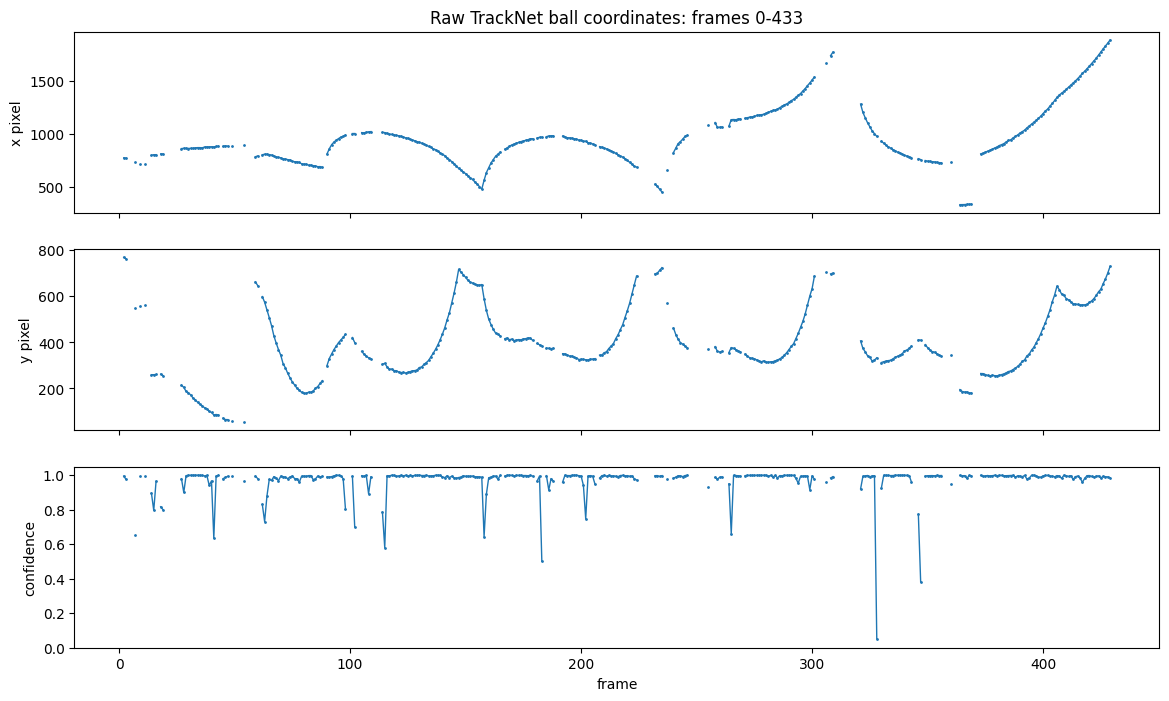

In [17]:
arr = np.full((len(ball_coords), 2), np.nan, dtype=np.float64)
for item in ball_coords:
    if item["pixel"] is not None:
        arr[item["frame_index"]] = item["pixel"]

preview_start = 0
preview_end = min(len(ball_coords), 500)
xs = np.arange(preview_start, preview_end)

conf_arr = np.full(len(ball_coords), np.nan, dtype=np.float64)
for item in ball_coords:
    if item.get("confidence") is not None:
        conf_arr[item["frame_index"]] = item["confidence"]

fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=True)
axes[0].plot(xs, arr[preview_start:preview_end, 0], marker=".", linewidth=1, markersize=2)
axes[1].plot(xs, arr[preview_start:preview_end, 1], marker=".", linewidth=1, markersize=2)
axes[2].plot(xs, conf_arr[preview_start:preview_end], marker=".", linewidth=1, markersize=2)
axes[0].set_ylabel("x pixel")
axes[1].set_ylabel("y pixel")
axes[2].set_ylabel("confidence")
axes[2].set_xlabel("frame")
axes[2].set_ylim(0, 1.05)
axes[0].set_title(f"Raw TrackNet ball coordinates: frames {preview_start}-{preview_end}")
plt.show()


## 6. Render Raw Detection Overlay Video

This writes the raw TrackNet detections back onto the source video. It is intentionally pre-optimization: use it to inspect whether the detector is finding the ball before trajectory cleanup.

In [18]:
def render_raw_ball_overlay(
    input_video_path,
    output_video_path,
    ball_coords,
    *,
    fps,
    frame_width,
    frame_height,
    tail_len=18,
    ball_radius=7,
):
    cap = cv2.VideoCapture(str(input_video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video for rendering: {input_video_path}")

    output_video_path = Path(output_video_path)
    output_video_path.parent.mkdir(parents=True, exist_ok=True)
    writer = cv2.VideoWriter(
        str(output_video_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps if fps > 0 else 25.0,
        (frame_width, frame_height),
    )
    if not writer.isOpened():
        cap.release()
        raise RuntimeError(f"Could not open video writer: {output_video_path}")

    coord_by_frame = {item["frame_index"]: item.get("pixel") for item in ball_coords}
    confidence_by_frame = {item["frame_index"]: item.get("confidence") for item in ball_coords}
    detected_count = sum(pixel is not None for pixel in coord_by_frame.values())
    total_count = len(ball_coords)
    rendered_count = 0
    progress = tqdm(total=total_count, desc="Render raw ball overlay")

    for frame_index in range(total_count):
        ok, frame = cap.read()
        if not ok:
            break
        canvas = frame.copy()

        # Draw short tracked-detection tail.
        for tail_frame in range(max(0, frame_index - tail_len), frame_index):
            p1 = coord_by_frame.get(tail_frame)
            p2 = coord_by_frame.get(tail_frame + 1)
            if p1 is None or p2 is None:
                continue
            alpha = (tail_frame - max(0, frame_index - tail_len) + 1) / max(tail_len, 1)
            color = (0, int(160 * alpha), int(255 * alpha))
            cv2.line(
                canvas,
                (int(round(p1[0])), int(round(p1[1]))),
                (int(round(p2[0])), int(round(p2[1]))),
                color,
                2,
                cv2.LINE_AA,
            )

        pixel = coord_by_frame.get(frame_index)
        if pixel is not None:
            x, y = int(round(pixel[0])), int(round(pixel[1]))
            confidence = confidence_by_frame.get(frame_index)
            confidence_value = float(confidence) if confidence is not None else 0.0
            confidence_value = float(np.clip(confidence_value, 0.0, 1.0))
            point_color = (0, int(80 + 175 * confidence_value), int(255 * (1.0 - 0.45 * confidence_value)))
            cv2.circle(canvas, (x, y), ball_radius + 3, (0, 0, 0), -1, cv2.LINE_AA)
            cv2.circle(canvas, (x, y), ball_radius, point_color, -1, cv2.LINE_AA)
            cv2.circle(canvas, (x, y), ball_radius + 1, (0, 120, 220), 1, cv2.LINE_AA)
            cv2.drawMarker(canvas, (x, y), (255, 255, 255), cv2.MARKER_CROSS, 12, 1, cv2.LINE_AA)

        current_confidence = confidence_by_frame.get(frame_index)
        confidence_text = f"conf={current_confidence:.3f}" if current_confidence is not None else "conf=None"
        hud_lines = [
            f"frame {frame_index}/{total_count - 1}",
            f"tracked ball detections: {detected_count}/{total_count} ({detected_count / max(total_count, 1):.1%})",
            f"current {confidence_text}",
            "point color = tracked candidate confidence",
        ]
        for line_index, text in enumerate(hud_lines):
            y_pos = 32 + line_index * 26
            cv2.putText(canvas, text, (20, y_pos), cv2.FONT_HERSHEY_SIMPLEX, 0.62, (0, 0, 0), 4, cv2.LINE_AA)
            cv2.putText(canvas, text, (20, y_pos), cv2.FONT_HERSHEY_SIMPLEX, 0.62, (255, 255, 255), 1, cv2.LINE_AA)

        writer.write(canvas)
        rendered_count += 1
        progress.update(1)

    cap.release()
    writer.release()
    progress.close()
    return rendered_count


rendered_frames = render_raw_ball_overlay(
    INPUT_VIDEO_PATH,
    RAW_POINTS_VIDEO_PATH,
    ball_coords,
    fps=fps,
    frame_width=frame_width,
    frame_height=frame_height,
)
print(f"wrote overlay video: {RAW_POINTS_VIDEO_PATH} ({rendered_frames} frames)")

Render raw ball overlay: 100%|██████████| 433/433 [00:03<00:00, 140.65it/s]

wrote overlay video: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/ball_coords_raw_overlay.mp4 (433 frames)


In [19]:
# ===== 新增：每帧所有候选点预览 =====
CANDIDATE_POINTS_VIDEO_PATH = OUTPUT_DIR / "ball_candidates_overlay.mp4"


def render_candidate_ball_overlay(
    input_video_path,
    output_video_path,
    ball_coords,
    *,
    fps,
    frame_width,
    frame_height,
    tail_len=18,
    ball_radius=7,
):
    cap = cv2.VideoCapture(str(input_video_path))
    if not cap.isOpened():
        raise RuntimeError(f"Could not open video for rendering: {input_video_path}")

    output_video_path = Path(output_video_path)
    output_video_path.parent.mkdir(parents=True, exist_ok=True)
    writer = cv2.VideoWriter(
        str(output_video_path),
        cv2.VideoWriter_fourcc(*"mp4v"),
        fps if fps > 0 else 25.0,
        (frame_width, frame_height),
    )
    if not writer.isOpened():
        cap.release()
        raise RuntimeError(f"Could not open video writer: {output_video_path}")

    tracked_by_frame = {item["frame_index"]: item.get("pixel") for item in ball_coords}
    postprocess_by_frame = {item["frame_index"]: item.get("postprocess_pixel") for item in ball_coords}
    raw_candidates_by_frame = {item["frame_index"]: item.get("raw_candidates", []) for item in ball_coords}
    candidates_by_frame = {item["frame_index"]: item.get("candidates", []) for item in ball_coords}
    total_count = len(ball_coords)
    raw_candidate_count = sum(len(item.get("raw_candidates", [])) for item in ball_coords)
    cluster_count = sum(len(item.get("candidates", [])) for item in ball_coords)
    rendered_count = 0
    progress = tqdm(total=total_count, desc="Render candidate overlay")

    palette = [
        (0, 210, 255),
        (255, 120, 0),
        (255, 0, 255),
        (0, 255, 140),
        (255, 255, 0),
        (120, 180, 255),
        (255, 120, 180),
    ]

    for frame_index in range(total_count):
        ok, frame = cap.read()
        if not ok:
            break
        canvas = frame.copy()

        raw_candidates = raw_candidates_by_frame.get(frame_index, [])
        candidates = candidates_by_frame.get(frame_index, [])

        # Small gray dots show raw Hough circles before clustering.
        for raw_candidate in raw_candidates:
            pixel = raw_candidate.get("pixel")
            if not pixel:
                continue
            x, y = int(round(pixel[0])), int(round(pixel[1]))
            cv2.circle(canvas, (x, y), max(2, ball_radius - 3), (120, 120, 120), -1, cv2.LINE_AA)

        # Larger colored dots show clustered candidate balls after de-duplication.
        for candidate in candidates:
            pixel = candidate.get("pixel")
            if not pixel:
                continue
            x, y = int(round(pixel[0])), int(round(pixel[1]))
            rank = int(candidate.get("rank") or 0)
            color = palette[(max(rank, 1) - 1) % len(palette)]
            member_count = int(candidate.get("member_count") or 1)
            label = f"{rank}({member_count})"
            cv2.circle(canvas, (x, y), ball_radius + 6, (0, 0, 0), -1, cv2.LINE_AA)
            cv2.circle(canvas, (x, y), ball_radius + 1, color, -1, cv2.LINE_AA)
            cv2.circle(canvas, (x, y), ball_radius + 2, (255, 255, 255), 1, cv2.LINE_AA)
            cv2.putText(
                canvas,
                label,
                (x + 10, y - 8),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.52,
                (0, 0, 0),
                3,
                cv2.LINE_AA,
            )
            cv2.putText(
                canvas,
                label,
                (x + 10, y - 8),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.52,
                (255, 255, 255),
                1,
                cv2.LINE_AA,
            )

        postprocess_pixel = postprocess_by_frame.get(frame_index)
        if postprocess_pixel is not None:
            x, y = int(round(postprocess_pixel[0])), int(round(postprocess_pixel[1]))
            cv2.drawMarker(canvas, (x, y), (0, 255, 255), cv2.MARKER_CROSS, 16, 2, cv2.LINE_AA)

        tracked_pixel = tracked_by_frame.get(frame_index)
        if tracked_pixel is not None:
            x, y = int(round(tracked_pixel[0])), int(round(tracked_pixel[1]))
            cv2.drawMarker(canvas, (x, y), (0, 255, 0), cv2.MARKER_TILTED_CROSS, 20, 2, cv2.LINE_AA)
            cv2.circle(canvas, (x, y), ball_radius + 2, (0, 0, 0), 1, cv2.LINE_AA)

        hud_lines = [
            f"frame {frame_index}/{total_count - 1}",
            f"raw Hough circles: {len(raw_candidates)}  clusters: {len(candidates)}",
            f"total raw: {raw_candidate_count}  total clusters: {cluster_count}",
            "gray=raw, colored=clustered, yellow=old postprocess, green=Viterbi-lite",
        ]
        for line_index, text in enumerate(hud_lines):
            y_pos = 32 + line_index * 26
            cv2.putText(canvas, text, (20, y_pos), cv2.FONT_HERSHEY_SIMPLEX, 0.62, (0, 0, 0), 4, cv2.LINE_AA)
            cv2.putText(canvas, text, (20, y_pos), cv2.FONT_HERSHEY_SIMPLEX, 0.62, (255, 255, 255), 1, cv2.LINE_AA)

        writer.write(canvas)
        rendered_count += 1
        progress.update(1)

    cap.release()
    writer.release()
    progress.close()
    return rendered_count


candidate_rendered_frames = render_candidate_ball_overlay(
    INPUT_VIDEO_PATH,
    CANDIDATE_POINTS_VIDEO_PATH,
    ball_coords,
    fps=fps,
    frame_width=frame_width,
    frame_height=frame_height,
)
print(f"wrote candidate overlay video: {CANDIDATE_POINTS_VIDEO_PATH} ({candidate_rendered_frames} frames)")


Render candidate overlay: 100%|██████████| 433/433 [00:03<00:00, 141.77it/s]

wrote candidate overlay video: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/ball_candidates_overlay.mp4 (433 frames)


## 7. Write JSON Outputs

In [20]:
metadata = {
    "version": "ball-coords-1.0.0",
    "source_video": INPUT_VIDEO_PATH.name,
    "source_video_path": str(INPUT_VIDEO_PATH),
    "ball_model_path": str(BALL_MODEL_PATH),
    "fps": fps,
    "video_width": frame_width,
    "video_height": frame_height,
    "total_frames": len(ball_coords),
    "generated_at": datetime.now(timezone.utc).isoformat(),
}

raw_payload = {
    "metadata": metadata,
    "ball_coords": ball_coords,
    "summary": {
        "detected_frames": detected,
        "tracked_detected_frames": tracked_detected,
        "postprocess_detected_frames": postprocess_detected,
        "missing_frames": len(ball_coords) - detected,
        "detection_ratio": round(detected / max(len(ball_coords), 1), 4),
        "confidence_method": f"softmax_probability_intensity_ge_{BALLNESS_CLASS_THRESHOLD}",
        "confidence_mean": round(float(np.mean(valid_confidences)), 4) if valid_confidences else None,
        "confidence_p10": round(float(np.percentile(valid_confidences, 10)), 4) if valid_confidences else None,
        "confidence_p50": round(float(np.percentile(valid_confidences, 50)), 4) if valid_confidences else None,
        "confidence_p90": round(float(np.percentile(valid_confidences, 90)), 4) if valid_confidences else None,
        "tracking_method": "viterbi_lite_candidates_effective_dt_raw_jump_gate_reacquire",
    },
}

def ball_payload_from_coord_item(item):
    if item["pixel"] is None:
        return None
    return {
        "pixel": item["pixel"],
        "court": None,
        "confidence": item.get("confidence"),
        "heat_conf": item.get("heat_conf"),
        "peak_class_probability": item.get("peak_class_probability"),
        "predicted_intensity": item.get("predicted_intensity"),
        "confidence_method": item.get("confidence_method"),
    }

match_frames_payload = {
    "metadata": {
        **metadata,
        "version": "2.0.0-ball-only",
        "court_dimensions": {"unit": "meters", "width": 10.97, "length": 23.77},
    },
    "frames": [
        {
            "frame_index": item["frame_index"],
            "time_sec": item["time_sec"],
            "court_visible": False,
            "court_keypoints_detected": 0,
            "ball": ball_payload_from_coord_item(item),
            "players": [],
            "events": {
                "is_bounce": False,
                "is_hit": False,
                "is_net_hit": False,
            },
        }
        for item in ball_coords
    ],
}

RAW_OUTPUT_PATH.write_text(json.dumps(raw_payload, ensure_ascii=False, indent=2), encoding="utf-8")
MATCH_FRAMES_OUTPUT_PATH.write_text(json.dumps(match_frames_payload, ensure_ascii=False, separators=(",", ":")), encoding="utf-8")

print("wrote:", RAW_OUTPUT_PATH, f"({RAW_OUTPUT_PATH.stat().st_size / 1024:.1f} KB)")
print("wrote:", MATCH_FRAMES_OUTPUT_PATH, f"({MATCH_FRAMES_OUTPUT_PATH.stat().st_size / 1024:.1f} KB)")


wrote: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/ball_coords_raw.json (2655.1 KB)
wrote: /Users/mac/PycharmProjects/tennis_data_master/cv/data/output/ball_coords_match_frames.json (137.2 KB)


## 8. Feed Into Trajectory Lab

Open `trajectory_optimization_lab.ipynb`. It now defaults to `cv/data/output/ball_coords_match_frames.json` when that file exists.

You can also explicitly set:

```python
MATCH_FRAMES_PATH = CV_OUTPUT_DIR / "ball_coords_match_frames.json"
```

or use the compact format:

```python
MATCH_FRAMES_PATH = CV_OUTPUT_DIR / "ball_coords_raw.json"
```